# K-means
- 无监督聚类
- 每个簇用一个 __质心(centroid)__ 代表,也就是簇内所有点的均值。
- 每个点到其所属质心的距离平方和,也叫 ___`簇内误差平方和(SSE / inertia)`___ ，即`K-means`的损失函数
- $J = \sum_{k=1}^{K}\sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$
- 对该损失函数求导，很容易得到梯度——即 ___样本均值___

## K-means++
- 离已有中心越远的样本，越有机会成为下一个中心
> 1. 从所有样本中等概率随机选择一个，作为第一个中心。
> 2. 对每个样本，找到离它最近的已选中心，计算两者的平方距离。
> 3. 按这些平方距离分配概率，随机抽取下一个中心。
> 4. 加入新中心后，重新计算距离和概率，直到选满 k 个中心。

# 颜色量化 color quantization
常用于压缩图片：用少量相近的颜色替代原来的大量颜色，让图片占用更少的存储空间，同时尽量保留原来的样子

- 读取图片
> 1. 读取图片
> 2. 缩放
> 3. 拉伸宽高

In [101]:
import torch
import numpy as np
from PIL import Image
from sklearn.datasets import load_sample_image

original = load_sample_image("china.jpg")
image = Image.fromarray(original).resize((96, 64))
image_array = np.array(image)
pixel_rows = torch.tensor(image_array, dtype=torch.float32).reshape(-1, 3)
pixels = pixel_rows / 255

- **_执行K-means算法_**

- 声明距离函数

In [102]:
def squared_distances(points, _centers):
    diffs = points[:, None, :] - _centers[None, :, :]
    squared_dists = (diffs ** 2).sum(dim = 2)
    return squared_dists

- 使用 k-means++ 选取随机中心点

In [103]:
def kmeans_plus_plus_init(x: torch.Tensor, k: int, seed: int):
    # 初始化随机数生成器，保证全局抽样结果可复现
    generator = torch.Generator().manual_seed(seed)
    first_index = torch.randint(len(x), size=(1,), generator=generator).item()
    initial_indices = [first_index]

    while len(initial_indices) < k:
        _centers = x[initial_indices]

        # 1. 获取距离矩阵
        dist_matrix = squared_distances(x, _centers)

        # 2. 提取每个点到【最近】中心的距离 (通过 view 强行对齐为二维，防止单个中心时 min(dim=1) 报错)
        nearest_squared = dist_matrix.view(len(x), -1).min(dim=1).values

        # 3. 抹平因浮点数运算误差导致的负数距离
        nearest_squared = torch.clamp(nearest_squared, min=0.0)

        # 4. 容错处理：如果所有距离均为 0，则退化为完全均匀抽样
        if nearest_squared.sum() <= 0:
            weights = torch.ones_like(nearest_squared)
        else:
            weights = nearest_squared # multinomial 自动处理未归一化权重

        # 5. 依概率抽样（核心：必须将 generator 传给 multinomial 保证 seed 生效）
        next_center_idx = torch.multinomial(weights, num_samples=1, generator=generator).item()

        initial_indices.append(next_center_idx)

    return initial_indices

In [104]:
def kmeans(points: torch.Tensor, k: int, seed=7, max_iterations=100):

    initial_indices = kmeans_plus_plus_init(points, k, seed)
    _centers = points[initial_indices].clone()

    distances = squared_distances(points, _centers)
    _losses = [distances.min(dim=1).values.sum().item()]
    _history = [_centers.clone()]

    for _ in range(max_iterations):
        # 每行取最小距离的列号，得到每个像素所属的簇编号。
        _labels = squared_distances(points, _centers).argmin(dim=1)
        # 取出同组像素，分别对 R、G、B 求平均；空簇沿用原来的中心。
        new_centers = _centers.clone()
        for group in range(k):
            members = points[_labels == group]
            if len(members) > 0:
                new_centers[group] = members.mean(dim=0)

        # 按更新后的代表色重新计算最近距离，记录本轮误差。
        _history.append(new_centers.clone())
        _losses.append(squared_distances(points, new_centers).min(dim=1).values.sum().item())
        # 所有代表色的 RGB 分量变化都小于 1e-5 时停止，最多更新 100 轮。
        converged = (new_centers - _centers).abs().max().item() < 1e-5
        _centers = new_centers
        if converged:
            break

    # 用最后一轮的调色板重新分组，确保重建时使用最终代表色。
    _labels = squared_distances(points, _centers).argmin(dim=1)
    return _centers, _labels, _history, _losses

- 代入数据

In [105]:
centers, labels, history, losses = kmeans(pixel_rows, k=3)
print(centers)
print(labels)
print(history)
print(losses)

tensor([[213.831, 224.317, 235.384],
        [ 51.860,  47.860,  36.202],
        [124.295, 112.919,  88.365]])
tensor([0, 0, 0,  ..., 1, 1, 1])
[tensor([[212., 215., 224.],
        [ 63.,  51.,  48.],
        [100., 115., 116.]]), tensor([[213.622, 223.755, 234.461],
        [ 58.661,  53.710,  38.887],
        [128.609, 117.375,  94.988]]), tensor([[214.005, 224.547, 235.702],
        [ 55.761,  51.662,  38.289],
        [128.989, 116.841,  93.065]]), tensor([[214.005, 224.547, 235.702],
        [ 54.751,  50.733,  37.887],
        [127.981, 115.983,  91.849]]), tensor([[213.986, 224.493, 235.607],
        [ 53.965,  49.886,  37.424],
        [126.849, 115.164,  90.860]]), tensor([[213.955, 224.453, 235.557],
        [ 53.404,  49.373,  37.076],
        [126.165, 114.546,  90.226]]), tensor([[213.930, 224.431, 235.538],
        [ 53.003,  48.953,  36.773],
        [125.627, 114.113,  89.794]]), tensor([[213.865, 224.356, 235.435],
        [ 52.786,  48.750,  36.666],
        [125.297

- 替换原像素

In [106]:
# 每个簇编号选出调色板中的一行，用代表色替换原像素。
quantized_pixels = centers[labels]
print("替换后的 RGB 样本形状：", tuple(quantized_pixels.shape))
print("前 5 个像素：原 RGB -> 代表色 RGB")
torch.set_printoptions(precision=3)
for before, after in zip(pixels[:5], quantized_pixels[:5]):
    print(before, "->", after)

替换后的 RGB 样本形状： (6144, 3)
前 5 个像素：原 RGB -> 代表色 RGB
tensor([0.686, 0.788, 0.906]) -> tensor([213.831, 224.317, 235.384])
tensor([0.686, 0.792, 0.910]) -> tensor([213.831, 224.317, 235.384])
tensor([0.690, 0.796, 0.914]) -> tensor([213.831, 224.317, 235.384])
tensor([0.694, 0.800, 0.918]) -> tensor([213.831, 224.317, 235.384])
tensor([0.698, 0.804, 0.922]) -> tensor([213.831, 224.317, 235.384])


In [107]:
# 按原来的高度和宽度折回去，像素重新落回原来的位置。
result = quantized_pixels.reshape(image_array.shape).numpy()
print("重建后的图片形状：", result.shape)

重建后的图片形状： (64, 96, 3)


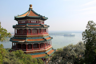

In [108]:
Image.fromarray(image_array)

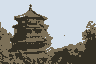

In [109]:
import numpy as np
result_uint8 = np.clip(result, 0, 255).astype(np.uint8)
Image.fromarray(result_uint8)